# 02 EDA and RFM segmentation

Real Olist orders, January 2017 to August 2018, from the tables built in notebook 01. Values are in Brazilian reais (R$).

Part A explores revenue, order behaviour, categories, geography, payment, and the delivery and review experience.

Part B scores every customer on recency, frequency and monetary value (RFM) and groups them into segments that fit a business where almost nobody buys twice.

Output: `data/processed/rfm_segments.csv`

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import olist as ol

ol.set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

orders = ol.load_orders()
cust = ol.load_customers()
done = orders[orders["completed"] == 1].copy()

pd.Series({
    "Customers": f"{len(cust):,}",
    "Completed orders": f"{len(done):,}",
    "GMV (items + freight)": ol.brl(done["order_value"].sum(), 2),
    "Average order value": ol.brl(done["order_value"].mean()),
    "Median order value": ol.brl(done["order_value"].median()),
    "Orders per customer": f"{len(done) / len(cust):.3f}",
    "Customers who ever came back": f"{cust['repeat_ever'].mean():.2%}",
}).to_frame("value")

,value
Customers,"94,703"
Completed orders,"97,905"
GMV (items + freight),R$15.68M
Average order value,R$160
Median order value,R$105
Orders per customer,1.034
Customers who ever came back,2.17%


## Part A: exploratory analysis

### A1. Revenue over time

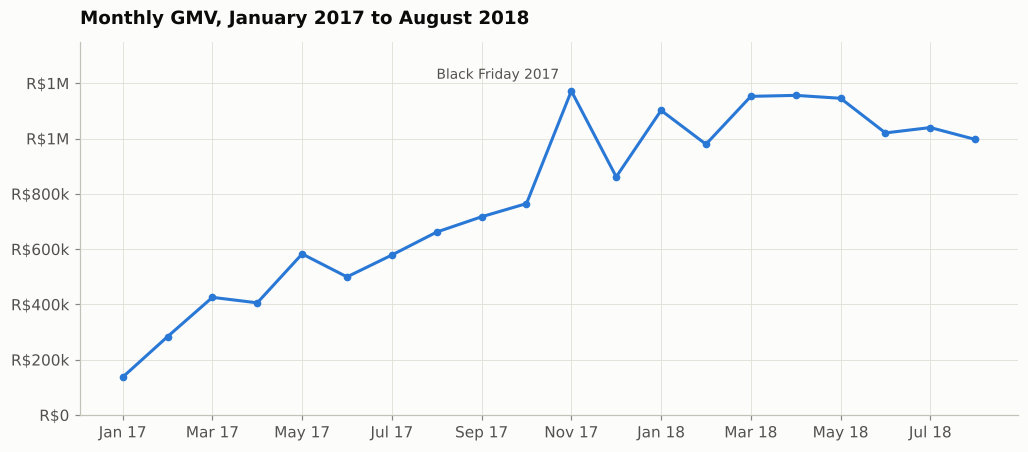

Busiest days:
purchase_ts
2017-11-24    1166
2017-11-25     498
2017-11-27     400
Median day: 150 orders


In [2]:
monthly = done.groupby(done["purchase_ts"].dt.to_period("M")).agg(gmv=("order_value", "sum"),
                                                                  orders=("order_id", "size"))
x = np.arange(len(monthly))

fig, ax = plt.subplots(figsize=(11, 4.4))
ax.plot(x, monthly["gmv"], marker="o", markersize=4, color=ol.SERIES[0])
nov = list(monthly.index.astype(str)).index("2017-11")
ax.annotate("Black Friday 2017", (nov, monthly["gmv"].iloc[nov]), textcoords="offset points", xytext=(-8, 8),
            ha="right", fontsize=9, color=ol.INK_2)
ax.set_xticks(x[::2], [p.strftime("%b %y") for p in monthly.index[::2]])
ax.set_ylim(0, monthly["gmv"].max() * 1.15)
ol.brl_axis(ax)
ax.set_title("Monthly GMV, January 2017 to August 2018")
ol.save(fig, "02_monthly_gmv")
plt.show()

daily = done.groupby(done["purchase_ts"].dt.date).size()
print("Busiest days:")
print(daily.sort_values(ascending=False).head(3).to_string())
print(f"Median day: {daily.median():.0f} orders")

Olist grew fast through 2017, then levelled off at about R$1.0M to R$1.15M a month in 2018. The one sharp spike is Black Friday: 24 November 2017 had 1,166 orders, about seven times a normal day.

### A2. Orders per customer

This is the chart that sets up the rest of the project. Purchases are counted by distinct day, so split carts don't inflate the count.

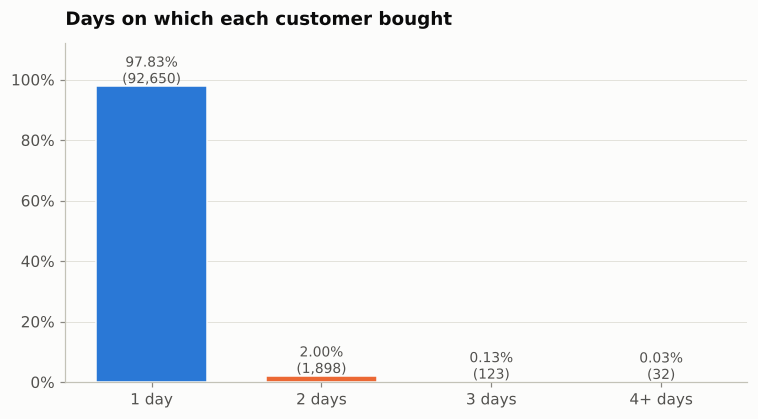

In [3]:
counts = cust["n_purchase_days"].clip(upper=4).value_counts().sort_index()
share = counts / counts.sum()

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(share.index, share.values, color=[ol.SERIES[0]] + [ol.SERIES[1]] * (len(share) - 1), width=0.65,
       edgecolor=ol.SURFACE)
for k, v in share.items():
    ax.text(k, v + 0.01, f"{v:.2%}\n({counts[k]:,})", ha="center", fontsize=9, color=ol.INK_2)
ax.set_xticks(share.index, ["1 day", "2 days", "3 days", "4+ days"])
ol.pct_axis(ax)
ax.set_ylim(0, 1.12)
ax.grid(axis="x", visible=False)
ax.set_title("Days on which each customer bought")
ol.save(fig, "02_purchase_days")
plt.show()

97.8% of customers bought on one day only. For an online retailer that is extreme: Olist sells through marketplaces under each shop's name, so most customers may not even know Olist was involved, and there is no account, app or loyalty scheme pulling them back. This is the problem the rest of the project is about.

### A3. Categories

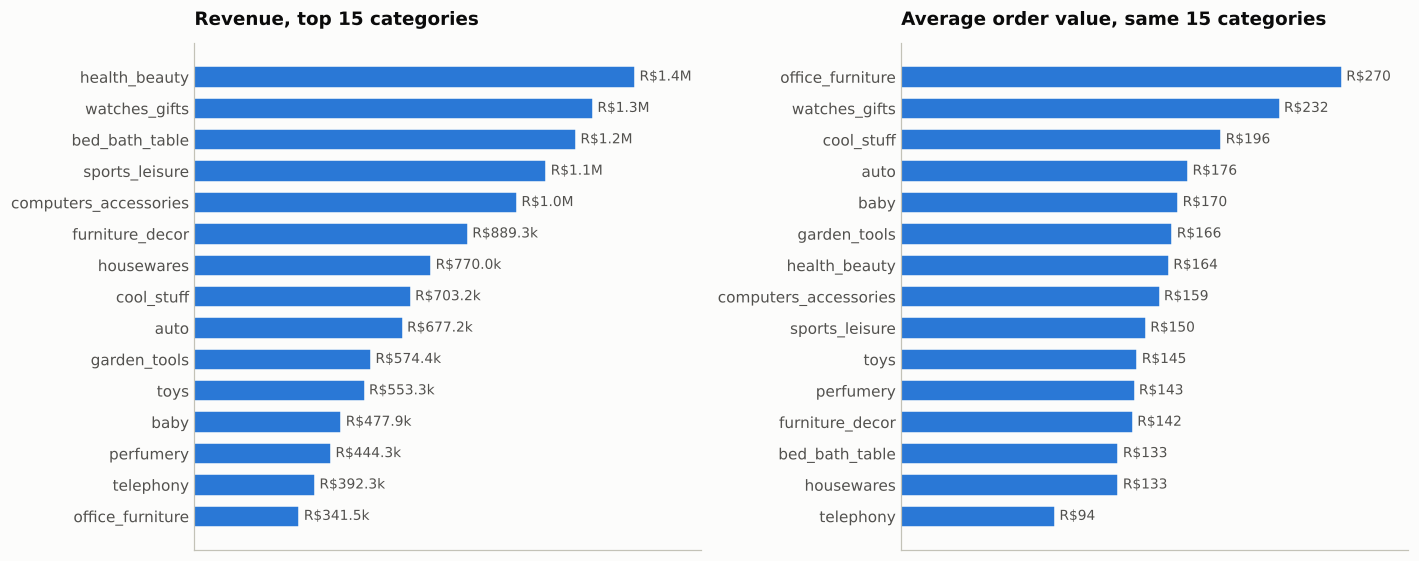

74 categories; the top 15 hold 76% of revenue.


In [4]:
cat = done.groupby("lead_category").agg(revenue=("order_value", "sum"), orders=("order_id", "size"),
                                        aov=("order_value", "mean"))
cat["revenue_share"] = cat["revenue"] / cat["revenue"].sum()
cat = cat.sort_values("revenue", ascending=False)
top = cat.head(15)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
ol.hbar(axes[0], top.index, top["revenue"], fmt=ol.brl)
axes[0].set_title("Revenue, top 15 categories")
axes[0].set_xticks([])
a = top.sort_values("aov", ascending=False)
ol.hbar(axes[1], a.index, a["aov"], fmt=ol.brl)
axes[1].set_title("Average order value, same 15 categories")
axes[1].set_xticks([])
fig.tight_layout()
ol.save(fig, "02_categories")
plt.show()

print(f"{len(cat)} categories; the top 15 hold {top['revenue_share'].sum():.0%} of revenue.")

Revenue is spread wide: no category has more than about 9% of it. Health and beauty, watches and gifts, and bed, bath and table lead. Office furniture (R$270) and watches and gifts (R$232) carry the highest order values among the top 15. Bed, bath and table and housewares sell a lot at about R$133 an order, and telephony (mostly accessories) is the cheapest at R$94.

### A4. Geography

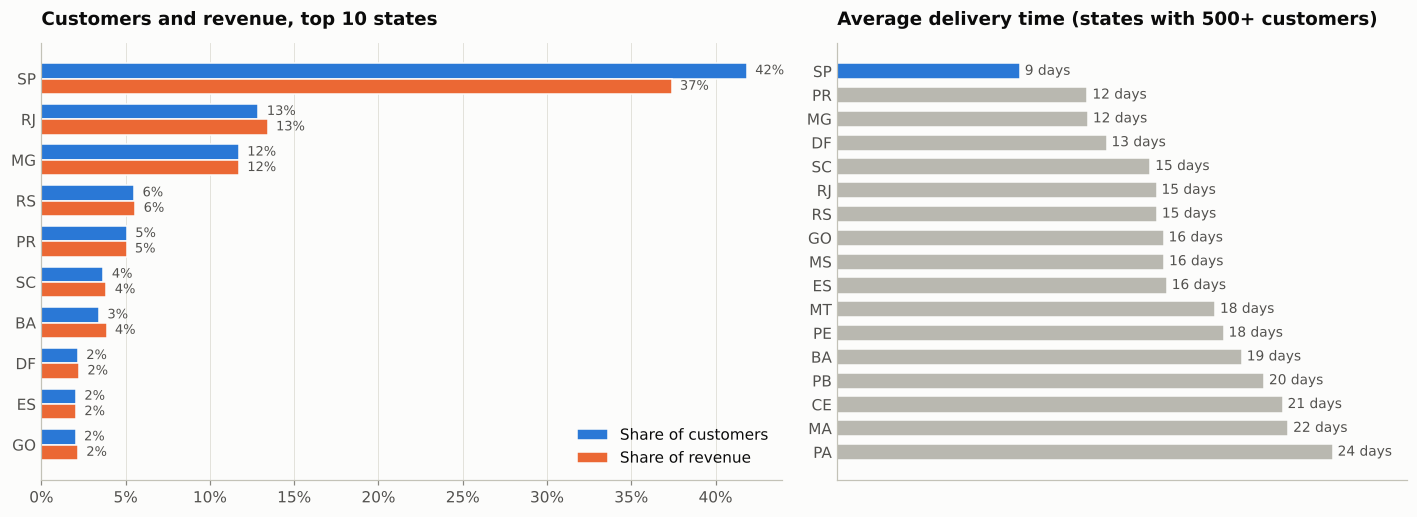

,customers,revenue,delivery_days,late_share,customer_share,revenue_share
customer_state,,,,,,
SP,"39,638",R$5.9M,8.7,5.9%,41.9%,37.4%
RJ,"12,196",R$2.1M,15.3,13.5%,12.9%,13.4%
MG,"11,095",R$1.8M,12.0,5.7%,11.7%,11.7%
RS,"5,212",R$873.7k,15.3,7.2%,5.5%,5.6%
PR,"4,804",R$792.1k,12.0,5.0%,5.1%,5.1%
SC,"3,488",R$604.7k,15.0,9.8%,3.7%,3.9%
BA,"3,240",R$606.2k,19.4,14.1%,3.4%,3.9%
DF,"2,050",R$350.2k,12.9,6.8%,2.2%,2.2%
ES,"1,945",R$321.9k,15.8,12.3%,2.1%,2.1%


In [5]:
st = cust.groupby("customer_state").agg(customers=("customer_unique_id", "size"), revenue=("total_spend", "sum"),
                                        delivery_days=("first_delivery_days", "mean"),
                                        late_share=("first_is_late", "mean"))
st["customer_share"] = st["customers"] / st["customers"].sum()
st["revenue_share"] = st["revenue"] / st["revenue"].sum()
st = st.sort_values("customers", ascending=False)
top10 = st.head(10)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.3, 1]})
ax = axes[0]
y = np.arange(len(top10))[::-1]
h = 0.38
ax.barh(y + h / 2, top10["customer_share"], height=h, color=ol.SERIES[0], label="Share of customers", edgecolor=ol.SURFACE)
ax.barh(y - h / 2, top10["revenue_share"], height=h, color=ol.SERIES[1], label="Share of revenue", edgecolor=ol.SURFACE)
for yi, c, r in zip(y, top10["customer_share"], top10["revenue_share"]):
    ax.text(c + 0.005, yi + h / 2, f"{c:.0%}", va="center", fontsize=8.5, color=ol.INK_2)
    ax.text(r + 0.005, yi - h / 2, f"{r:.0%}", va="center", fontsize=8.5, color=ol.INK_2)
ax.set_yticks(y, top10.index)
ax.tick_params(axis="y", length=0)
ax.grid(axis="y", visible=False)
ol.pct_axis(ax, axis="x")
ax.legend(loc="lower right")
ax.set_title("Customers and revenue, top 10 states")

d = st[st["customers"] >= 500].sort_values("delivery_days")
ol.hbar(axes[1], d.index, d["delivery_days"], fmt=lambda v: f"{v:.0f} days", highlight="SP")
axes[1].set_xticks([])
axes[1].set_title("Average delivery time (states with 500+ customers)")
fig.tight_layout()
ol.save(fig, "02_states")
plt.show()

st.head(12).style.format({"customers": "{:,}", "revenue": ol.brl, "delivery_days": "{:.1f}", "late_share": "{:.1%}",
                          "customer_share": "{:.1%}", "revenue_share": "{:.1%}"})

São Paulo state (SP) has 42% of customers and 37% of revenue. Most sellers are there too, so SP customers get their parcels in about 9 days. Customers in the north-east wait twice as long or more, and are late far more often: Bahia (BA) and Ceará (CE) see 14% to 16% of first orders arrive after the promised date, against 6% in SP. Customers further from SP spend a little more per head, which fits freight being a bigger part of the bill.

### A5. Payment

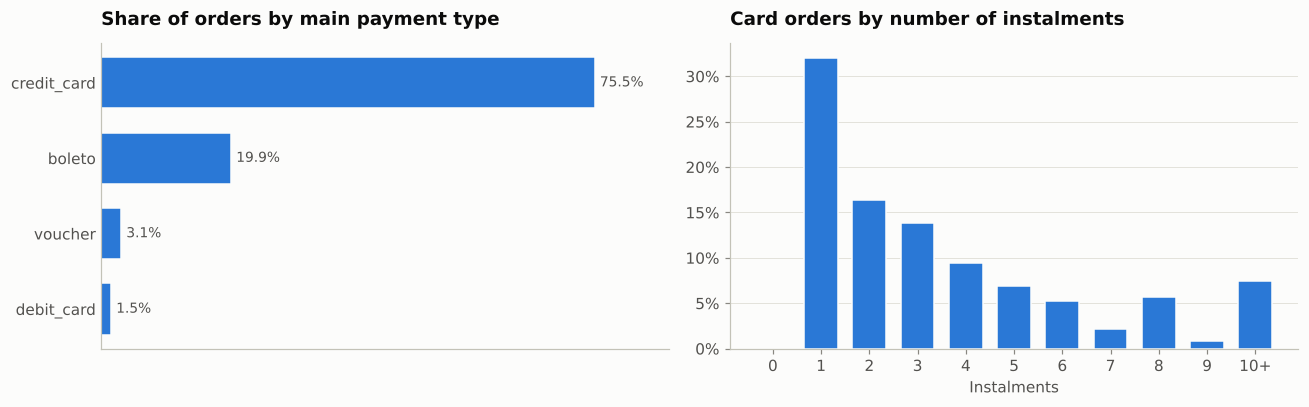

Card orders split into 2+ instalments: 68%


In [6]:
pay = done["payment_type"].value_counts(normalize=True)
inst = done.loc[done["payment_type"] == "credit_card", "installments"].clip(upper=10).value_counts(normalize=True).sort_index()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
ol.hbar(axes[0], pay.index, pay.values, fmt=lambda v: f"{v:.1%}")
axes[0].set_xticks([])
axes[0].set_title("Share of orders by main payment type")
axes[1].bar(inst.index, inst.values, color=ol.SERIES[0], width=0.7, edgecolor=ol.SURFACE)
axes[1].set_xticks(inst.index, [str(int(k)) if k < 10 else "10+" for k in inst.index])
ol.pct_axis(axes[1])
axes[1].grid(axis="x", visible=False)
axes[1].set_xlabel("Instalments")
axes[1].set_title("Card orders by number of instalments")
fig.tight_layout()
ol.save(fig, "02_payment")
plt.show()

print(f"Card orders split into 2+ instalments: {(done.loc[done['payment_type'] == 'credit_card', 'installments'] > 1).mean():.0%}")

Three orders in four are paid by card, and about one in five by boleto, a Brazilian bank slip paid in cash or online before the goods ship. Paying in instalments is normal in Brazil: most card orders are split, even small ones.

### A6. Delivery and reviews

Olist gives every order an estimated delivery date. The gap between that promise and what happened drives the review the customer leaves.

Median promised delivery: 23 days
Median actual delivery:   10 days
Delivered after the promised date: 8.1%


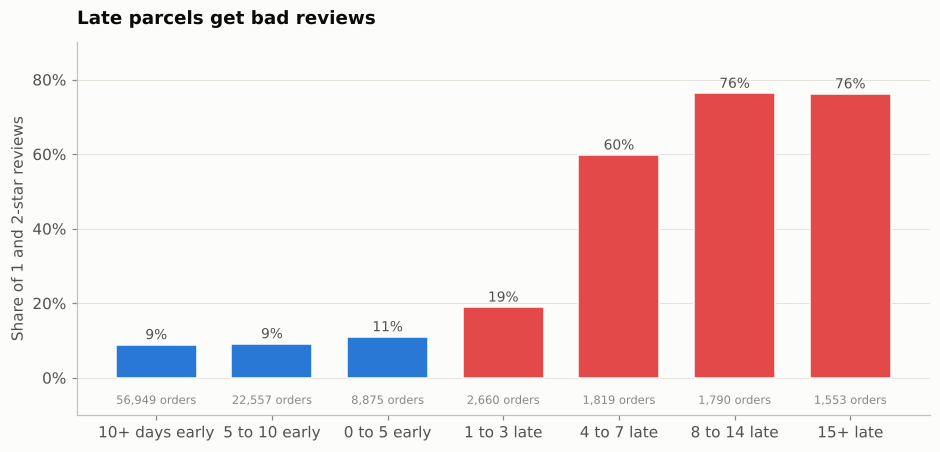

Late orders: 8.1% of delivered orders, 33.9% of all 1 and 2-star reviews


,orders,avg_score,bad_share
delay_band,,,
10+ days early,56949,4.32,0.09
5 to 10 early,22557,4.28,0.09
0 to 5 early,8875,4.15,0.11
1 to 3 late,2660,3.77,0.19
4 to 7 late,1819,2.32,0.60
8 to 14 late,1790,1.74,0.76
15+ late,1553,1.71,0.76


In [7]:
dl = done[done["delivered_ts"].notna()].copy()
print(f"Median promised delivery: {dl['promised_days'].median():.0f} days")
print(f"Median actual delivery:   {dl['delivery_days'].median():.0f} days")
print(f"Delivered after the promised date: {dl['is_late'].mean():.1%}")

bands = [-1000, -10, -5, 0, 3, 7, 14, 1000]
labels = ["10+ days early", "5 to 10 early", "0 to 5 early", "1 to 3 late", "4 to 7 late", "8 to 14 late", "15+ late"]
dl["delay_band"] = pd.cut(dl["delay_days"], bands, labels=labels)
rv = dl.groupby("delay_band", observed=True).agg(orders=("order_id", "size"), avg_score=("review_score", "mean"),
                                                 bad_share=("review_score", lambda s: (s <= 2).mean()))

fig, ax = plt.subplots(figsize=(10, 4.4))
xx = np.arange(len(rv))
colors = [ol.SERIES[0]] * 3 + [ol.SERIES[7]] * 4
ax.bar(xx, rv["bad_share"], color=colors, width=0.7, edgecolor=ol.SURFACE)
for xi, v, n in zip(xx, rv["bad_share"], rv["orders"]):
    ax.text(xi, v + 0.015, f"{v:.0%}", ha="center", fontsize=9, color=ol.INK_2)
    ax.text(xi, -0.07, f"{n:,} orders", ha="center", fontsize=7.5, color=ol.MUTED)
ax.set_xticks(xx, rv.index)
ax.set_ylim(-0.1, 0.9)
ol.pct_axis(ax)
ax.grid(axis="x", visible=False)
ax.set_ylabel("Share of 1 and 2-star reviews")
ax.set_title("Late parcels get bad reviews")
ol.save(fig, "02_delay_reviews")
plt.show()

bad = dl["review_score"] <= 2
print(f"Late orders: {dl['is_late'].mean():.1%} of delivered orders, "
      f"{(bad & (dl['is_late'] == 1)).sum() / bad.sum():.1%} of all 1 and 2-star reviews")
rv

Olist pads its promises: the median order is promised in 23 days and arrives in 10, so most parcels come early. That keeps bad reviews to about one in ten. Once a parcel is more than three days late, the picture flips: 60% of those customers leave one or two stars, and past a week it's three in four. About 8% of delivered orders arrive late, and they produce about a third of all 1 and 2-star reviews.

## Part B: RFM segmentation

### B1. Why the textbook segments don't fit

Standard RFM segments (Champions, Loyal, At Risk) assume customers buy repeatedly. Here 97.8% bought on a single day, so frequency is 1 for almost everyone and quintiles of frequency are meaningless. The scheme below keeps the RFM logic but adapts it:

1. Recency (R): days from last purchase to the snapshot, scored 1 to 5 by quintile (5 is most recent). For a one-time buyer this is simply how long ago they arrived.
2. Frequency (F): one purchase day, or two or more.
3. Monetary (M): total spend, scored 1 to 5 by quintile.

In [8]:
rfm = cust[["customer_unique_id", "last_purchase", "n_purchase_days", "total_spend"]].copy()
rfm["recency_days"] = (ol.SNAPSHOT_END - rfm["last_purchase"]).dt.days
rfm["R"] = pd.qcut(rfm["recency_days"].rank(method="first"), 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["M"] = pd.qcut(rfm["total_spend"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["F"] = np.where(rfm["n_purchase_days"] >= 2, 2, 1)

bounds = pd.DataFrame({
    "recency_days": rfm.groupby("R")["recency_days"].agg(["min", "max"]).astype(str).agg(" to ".join, axis=1),
    "spend": rfm.groupby("M")["total_spend"].agg(["min", "max"]).apply(
        lambda r: f"{ol.brl(r['min'])} to {ol.brl(r['max'])}", axis=1),
})
bounds.index.name = "score"
bounds

,recency_days,spend
score,,
1,383 to 603,R$10 to R$55
2,270 to 383,R$55 to R$87
3,179 to 270,R$87 to R$133
4,94 to 179,R$133 to R$209
5,2 to 94,R$209 to R$13.7k


### B2. Segment rules

Applied in order; the first match wins, so every customer lands in exactly one segment.

| Order | Segment | Rule |
|---|---|---|
| 1 | Repeat, active | F = 2+, R 3 to 5 |
| 2 | Repeat, lapsed | F = 2+, R 1 to 2 |
| 3 | New, high value | F = 1, R 4 to 5, M 4 to 5 |
| 4 | New | F = 1, R 4 to 5, M 1 to 3 |
| 5 | Cooling, high value | F = 1, R 2 to 3, M 4 to 5 |
| 6 | Cooling | F = 1, R 2 to 3, M 1 to 3 |
| 7 | Dormant, high value | F = 1, R = 1, M 4 to 5 |
| 8 | Dormant | F = 1, R = 1, M 1 to 3 |

"New" customers bought in the last few months and are the only one-time buyers still likely to come back; later notebooks show the odds fall away fast after the first few months.

In [9]:
SEGMENTS = ["Repeat, active", "Repeat, lapsed", "New, high value", "New", "Cooling, high value", "Cooling",
            "Dormant, high value", "Dormant"]


def segment(r, f, m):
    if f == 2:
        return "Repeat, active" if r >= 3 else "Repeat, lapsed"
    tier = "high value" if m >= 4 else None
    stage = "New" if r >= 4 else "Cooling" if r >= 2 else "Dormant"
    return f"{stage}, {tier}" if tier else stage


rfm["segment"] = pd.Categorical([segment(r, f, m) for r, f, m in zip(rfm["R"], rfm["F"], rfm["M"])],
                                categories=SEGMENTS, ordered=True)
seg = rfm.groupby("segment", observed=False).agg(customers=("R", "size"), avg_recency=("recency_days", "mean"),
                                                 avg_purchase_days=("n_purchase_days", "mean"),
                                                 avg_spend=("total_spend", "mean"), revenue=("total_spend", "sum"))
seg["customer_share"] = seg["customers"] / seg["customers"].sum()
seg["revenue_share"] = seg["revenue"] / seg["revenue"].sum()
seg.style.format({"customers": "{:,}", "avg_recency": "{:,.0f}", "avg_purchase_days": "{:.2f}", "avg_spend": ol.brl,
                  "revenue": ol.brl, "customer_share": "{:.1%}", "revenue_share": "{:.1%}"})

,customers,avg_recency,avg_purchase_days,avg_spend,revenue,customer_share,revenue_share
segment,,,,,,,
"Repeat, active","1,465",124,2.13,R$324,R$475.1k,1.5%,3.0%
"Repeat, lapsed",588,366,2.05,R$314,R$184.9k,0.6%,1.2%
"New, high value","14,707",93,1.00,R$303,R$4.5M,15.5%,28.5%
New,"22,091",91,1.00,R$73,R$1.6M,23.3%,10.3%
"Cooling, high value","14,447",269,1.00,R$296,R$4.3M,15.3%,27.2%
Cooling,"22,677",270,1.00,R$73,R$1.6M,23.9%,10.5%
"Dormant, high value","7,053",473,1.00,R$309,R$2.2M,7.4%,13.9%
Dormant,"11,675",472,1.00,R$73,R$848.1k,12.3%,5.4%


### B3. Segment size against revenue

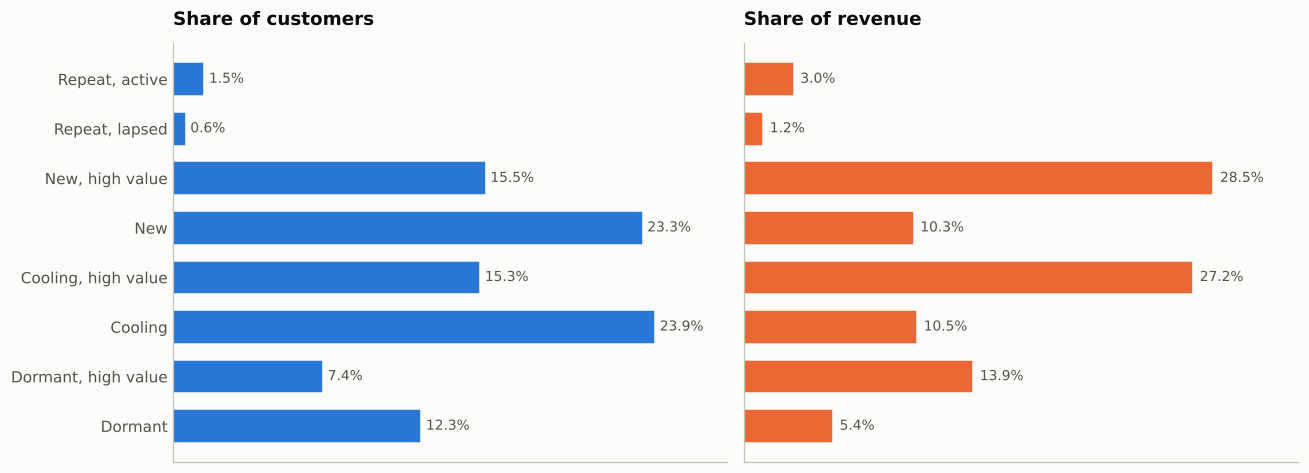

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
ol.hbar(axes[0], seg.index, seg["customer_share"], fmt=lambda v: f"{v:.1%}")
axes[0].set_title("Share of customers")
axes[0].set_xticks([])
y = np.arange(len(seg))[::-1]
axes[1].barh(y, seg["revenue_share"], color=ol.SERIES[1], height=0.68, edgecolor=ol.SURFACE)
for yi, v in zip(y, seg["revenue_share"]):
    axes[1].text(v + 0.004, yi, f"{v:.1%}", va="center", fontsize=9, color=ol.INK_2)
axes[1].set_xlim(0, seg["revenue_share"].max() * 1.18)
axes[1].grid(axis="y", visible=False)
axes[1].tick_params(axis="y", length=0)
axes[1].set_xticks([])
axes[1].set_title("Share of revenue")
fig.tight_layout()
ol.save(fig, "02_segment_size_revenue")
plt.show()

### B4. Segment profiles

Each column is shaded on its own scale; the numbers are the real averages.

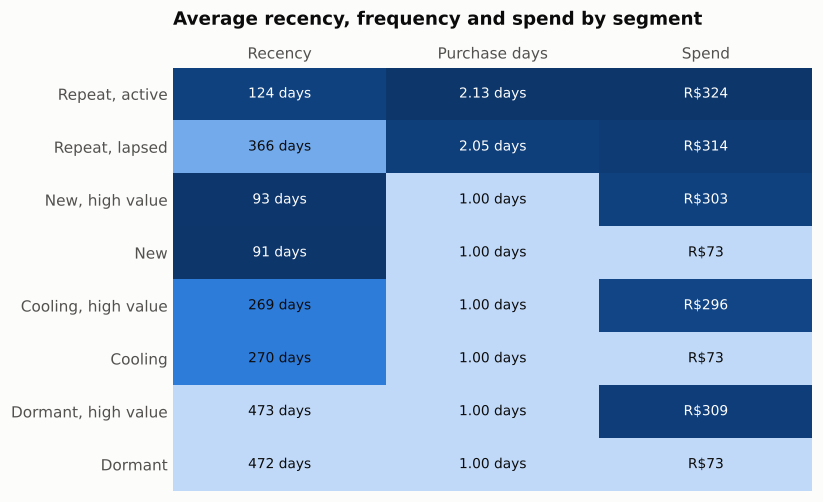

In [11]:
prof = seg[["avg_recency", "avg_purchase_days", "avg_spend"]]
shade = (prof - prof.min()) / (prof.max() - prof.min())
shade["avg_recency"] = 1 - shade["avg_recency"]

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.imshow(shade.to_numpy(), cmap=ol.SEQ_CMAP, aspect="auto", vmin=-0.05, vmax=1)
fmt = {"avg_recency": lambda v: f"{v:,.0f} days", "avg_purchase_days": lambda v: f"{v:.2f} days",
       "avg_spend": ol.brl}
for i in range(len(prof)):
    for j, col in enumerate(prof.columns):
        ax.text(j, i, fmt[col](prof.iloc[i, j]), ha="center", va="center", fontsize=9,
                color="white" if shade.iloc[i, j] > 0.55 else ol.INK)
ax.set_xticks(range(3), ["Recency", "Purchase days", "Spend"])
ax.set_yticks(range(len(prof)), prof.index)
ax.tick_params(length=0)
ax.grid(False)
for sp in ax.spines.values():
    sp.set_visible(False)
ax.xaxis.tick_top()
ax.set_title("Average recency, frequency and spend by segment", pad=28)
ol.save(fig, "02_segment_heatmap")
plt.show()

### B5. Export

In [12]:
out = rfm[["customer_unique_id", "recency_days", "n_purchase_days", "total_spend", "R", "F", "M", "segment"]].copy()
out["segment"] = out["segment"].astype(str)
out.to_csv(ol.PROCESSED / "rfm_segments.csv", index=False)
print(f"Wrote {len(out):,} rows to data/processed/rfm_segments.csv")

Wrote 94,703 rows to data/processed/rfm_segments.csv


## Findings

1. 97.8% of customers bought on a single day, and only 2.2% ever came back on a later day. Olist's revenue rests almost entirely on new customers.
2. GMV was R$15.7M over 20 months. It grew fast through 2017 and levelled off at about R$1.0M to R$1.15M a month in 2018. Black Friday 2017 was the biggest single day by far, at 1,166 orders.
3. São Paulo state holds 42% of customers and gets its parcels in about 9 days. North-eastern states wait 18 to 21 days, and 14% to 16% of their first orders arrive late, against 6% in SP.
4. Delivery drives reviews. Parcels that arrive early or on time get bad reviews about one time in ten. More than three days late, 60% to 76% of customers leave one or two stars. Late orders are 8% of deliveries but produce about a third of all bad reviews.
5. RFM shows where the money sits: one-time buyers who spent R$133 or more are 38% of customers and 70% of revenue. Customers who came back are only 2.1% of customers and 4.2% of revenue. The 39% of customers who bought in the last six months ("New" and "New, high value") are the only one-time buyers with a realistic chance of a second order, so they are the target for any retention push.